learning how to flow

In [5]:
%load_ext autoreload
%autoreload 2

# IMPORTS
import time
import tqdm
import math

import torch
from torch import nn
import numpy as np
# import torchdyn
from torchdyn.core import NeuralODE 


from data import * #only here bc you can plot the data for the main notebook, but is generallly used in the training loop inside flow_matching.py
from dpd import *
from model_architecture import * 
from transformer import *
# from utils import *
from flow_matching import * 
# from discrete_fm import *


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
####### DEVICE SETUP #######
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("device is", device)

device is mps


### Data & Sampling


**data.py**

Sample from the distributions (Cat or Moon)  
Data sits on -4 to 4.0 grid in the X-Y axis space  

**def sample_cats(N=1500):**  
&emsp;Samples N points from the cat distribution.  
&emsp;Return:  
&emsp;&emsp;numpy array of each xy coordinate in the sampled dist

**def sample_moons(N=1500):**  
&emsp;Uses the torchdfyn module to generate N samples of the moon distribution  
&emsp;Return:  
&emsp;&emsp;torch.tensor of each xy coordinate in the sampled dist. 

**def plot_distribution(sampled_points[list], dist_name[list],color[list]):**  
&emsp;Plots the sampled points, dist_name and color are lists of strings  

In [3]:
# ############ UNCOMMENT TO PLOT DISTRIBUTIONS ############
# #sample and plot cats
# sampled_cats = sample_cats(1500)
# # plot_distribution([sampled_cats], ["Cats"], ["gold"])
# #sample and plot moons
# sampled_moons = sample_moons(1500)
# # plot_distribution([sampled_moons], ["Moon"], ["steelblue"])
# #plot both together
# plot_distribution([sampled_moons, sampled_cats], ["Moon", "Cats"], ["steelblue", "gold"])

**dpd.py**

Generates some type of source distribution (symmetric or binomial) and applies a discrete process to it (poisson) to generate the target distribution

In [27]:
SEED = 10
N = 1000
rng = np.random.default_rng(SEED)
CENTERS = [20, 3]
N_MEASURES = 2
#initialize the data object using the list of centers
# spec = make_measure_specs(centers=CENTERS, seed=SEED)

#initialize the data object using the list of centers
spec = make_measure_specs(n_measures=N_MEASURES, seed=SEED)
#create the source and target according to the spec parameters
#processed is the timesteps of the discrete process
for s in spec:
    processed = generate_target_dist(spec=s, sample_size=N, rng=rng)
    # plot_dpd(processed, sample_type=s.sample_type, process_type=s.process_type, center=s.center)
    animate_discrete_histograms(
        processed,                         # (T, N) trajectory: rows are timesteps
        V=int(processed.max()) + 1,        # number of bins, must cover the largest count
        target=processed[-1],              # last timestep = target distribution
        center=s.center,                   # dashed line at the source center
        title_prefix=f"{s.process_type.upper()} Process applied to a {s.sample_type.upper()} Distribution (center {s.center})"
        )

### Discrete Flow Matching

/Users/magui/miniconda3/lib/python3.12/site-packages/torch/nn/init.py:511: UserWarning: Initializing zero-element tensors is a no-op
  warnings.warn("Initializing zero-element tensors is a no-op")


128 outdim
model on device: mps
Epoch:0: loss 4.852 time 0.12
[ 0  2  3  5  7  8 10 12 13 15 17 18 20 22 23 25 27 29 30 32 34 35 37 39
 40 42 44 45 47 49 50 52 54 55 57 59 60 62 64 65 67 69 70 72 74 76 77 79
 81 82 84 86 87 89 91 92 94 96 97 99]
i is 0
i is 0
i is 2
i is 3
i is 5
i is 7
i is 8
i is 10
i is 12
i is 13
i is 15
i is 17
i is 18
i is 20
i is 22
i is 23
i is 25
i is 27
i is 29
i is 30
i is 32
i is 34
i is 35
i is 37
i is 39
i is 40
i is 42
i is 44
i is 45
i is 47
i is 49
i is 50
i is 52
i is 54
i is 55
i is 57
i is 59
i is 60
i is 62
i is 64
i is 65
i is 67
i is 69
i is 70
i is 72
i is 74
i is 76
i is 77
i is 79
i is 81
i is 82
i is 84
i is 86
i is 87
i is 89
i is 91
i is 92
i is 94
i is 96
i is 97
i is 99
i is 0
i is 0
i is 2
i is 3
i is 5
i is 7
i is 8
i is 10
i is 12
i is 13
i is 15
i is 17
i is 18
i is 20
i is 22
i is 23
i is 25
i is 27
i is 29
i is 30
i is 32
i is 34
i is 35
CPU times: user 8.8 s, sys: 721 ms, total: 9.52 s
Wall time: 9.58 s


KeyboardInterrupt: 

i is 0


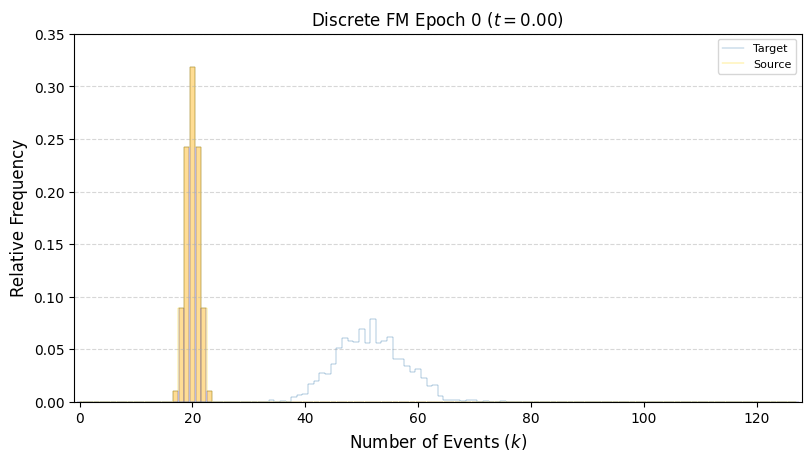

In [8]:
%%time

# key is the dataset name, value is the dimension
data_dict = {"dpd":1,
             "catmoons": 2}
data = "dpd" #"catmoons" "dpd"
dim = data_dict[data]
V = 128
#set up the model and optimizer
# model = MLP(dim=dim, out_dim = dim * V, w=512, time_varying=True).to(device)
model = DiscreteAttentionFlow(
            D=dim,
            out_dim = dim * V,
            num_hidden=64,
            num_layers=3,
            num_heads=1,
            num_ffn_layers=2,
            num_conditions=None,
            activation=nn.GELU,
            dropout=0.05,
        ).to(device)


optimizer = torch.optim.Adam(model.parameters())
print(f"model on device: {device}")


dfm = DiscreteFlowMatching(optimizer, device, model, V, data)
#training loop
dfm.train(epochs=20000, batch_size = 256)

### OG Conditional Flow Matching

In [ ]:
%%time
#2D distribution so dim is 2
dim = 2
#set up the model and optimizer
model = MLP(dim=dim, time_varying=True).to(device)
optimizer = torch.optim.Adam(model.parameters())
print(f"model on device: {device}")

fm = FlowMatching(optimizer, device, model)
#training loop
fm.train()